# Conceptos de la mentora vs `concepts.py`

¿Cuántas empresas sobrevivientes tienen todos los conceptos en los 24 trimestres? El notebook mide tres opciones. Cada una agrega a la anterior, no saca nada:

1. **Mentora:** los tags y las construcciones de la guía (`docs/professor-materials/sec-edgar-guide.docx`, sección 4).
2. **+ `concepts.py`:** la opción 1 más nuestros tags.
3. **+ construcciones:** la opción 2 más nuestras construcciones (`docs/ratios.md`).

Prioridad: en cada empresa, concepto y período, se usa el valor de la opción 1. Si no hay, el de la opción 2. Si tampoco hay, el de la opción 3. Si no hay ninguno, el período queda sin valor.

Solo se usan los 9 conceptos de los 7 ratios elegidos (`docs/ratios.md`). La guía tiene una sola construcción, `GrossProfit` = `Revenues` − `CostOfRevenue`. Es del margen bruto, un ratio descartado, así que no entra en los 9 conceptos.

In [1]:
import sys
from pathlib import Path

import pandas as pd


if "google.colab" in sys.modules:
    from google.colab import drive  # type: ignore

    drive.mount("/content/drive")

    CANDIDATOS = [
        Path("/content/drive/MyDrive/Colab Notebooks/Diplodatos MAI Grupo 6"),
        Path("/content/drive/MyDrive/Diplodatos MAI Grupo 6"),
    ]
    WORKING_DIR = next((p for p in CANDIDATOS if p.exists()), None)
    if WORKING_DIR is None:
        raise FileNotFoundError(
            "No encuentro la carpeta del grupo. ¿Agregaste el acceso directo "
            "en 'Mi unidad' desde 'Compartido conmigo'?"
        )
else:
    WORKING_DIR = Path.cwd()

# `shared/` is next to the notebooks (in Colab, inside the group folder)
sys.path.append(str(WORKING_DIR))
from shared.concepts import CONCEPTS

## Sobrevivientes

Mismo criterio que `survivorship_bias.ipynb`: una presentación (10-K o 10-Q) con `period` en cada uno de los 24 trimestres 2018–2023. El sector es el del documento más reciente por `filed`.

In [2]:
sub = pd.read_csv(f"{WORKING_DIR}/data/sub.csv", dtype=str)
sub["quarter"] = pd.to_datetime(sub["period"], format="%Y%m%d").dt.to_period("Q")
sub = sub[sub["quarter"].between(pd.Period("2018Q1"), pd.Period("2023Q4"))]

quarters = sub.groupby("cik")["quarter"].nunique()
survivors = quarters[quarters == 24].index
sector = sub.sort_values("filed").groupby("cik")["sector"].last()[survivors]
sector.value_counts()

sector
energy    101
health     42
Name: count, dtype: int64

## Tags de la mentora

`MENTOR` copia la tabla de la guía para los 9 conceptos. La celda muestra los tags de la mentora que no están en `concepts.py`.

In [3]:
MENTOR = {
    "revenue": [
        "Revenues",
        "SalesRevenueNet",
        "RevenueFromContractWithCustomerExcludingAssessedTax",
    ],
    "operating_income": ["OperatingIncomeLoss"],
    "net_income": ["NetIncomeLoss", "ProfitLoss"],
    "assets": ["Assets"],
    "liabilities": ["Liabilities"],
    "equity": ["StockholdersEquity", "StockholdersEquityAttributableToParent"],
    "current_assets": ["AssetsCurrent"],
    "current_liabilities": ["LiabilitiesCurrent"],
    "operating_cash_flow": ["NetCashProvidedByUsedInOperatingActivities"],
}


print("tags de la mentora que no están en el diccionario de conceptos:")
{
    concept: [t for t in MENTOR[concept] if t not in CONCEPTS[concept]]
    for concept in MENTOR
    if set(MENTOR[concept]) - set(CONCEPTS[concept])
}

tags de la mentora que no están en el diccionario de conceptos:


{'net_income': ['ProfitLoss'],
 'equity': ['StockholdersEquityAttributableToParent']}

## Valores por período

`values` tiene una fila por período (`cik`, `ddate`, `qtrs`) y una columna por tag. Solo trae los tags que usan las tres opciones. `col` y `first` son las mismas funciones de `concepts_justification.ipynb`.

Nuestras construcciones son las de `docs/ratios.md`. La tabla de fuentes, más abajo, las lista.

In [4]:
TOTAL_EQUITY = [
    "StockholdersEquityIncludingPortionAttributableToNoncontrollingInterest",
    "StockholdersEquity",
    "PartnersCapitalIncludingPortionAttributableToNoncontrollingInterest",
    "PartnersCapital",
    "MembersEquity",
]
TEMPORARY_EQUITY = [
    "TemporaryEquityCarryingAmountAttributableToParent",
    "RedeemableNoncontrollingInterestEquityCarryingAmount",
]
BUILD_TAGS = (
    TOTAL_EQUITY
    + TEMPORARY_EQUITY
    + [
        "CostsAndExpenses",
        "ProfitLoss",
        "NetIncomeLossAttributableToNoncontrollingInterest",
        "LiabilitiesAndStockholdersEquity",
        "MinorityInterest",
    ]
)
TAGS = {t for tags in [*MENTOR.values(), *CONCEPTS.values(), BUILD_TAGS] for t in tags}

num = pd.read_csv(
    f"{WORKING_DIR}/data/num.csv",
    dtype={"cik": str, "ddate": str, "qtrs": str},
    usecols=["cik", "tag", "ddate", "qtrs", "value"],
)
num = num[num["cik"].isin(survivors) & num["tag"].isin(TAGS)]
num = num[num["ddate"].between("20180101", "20231231")]

# one row per period and one column per tag; NaN = the company did not report that tag
values = num.pivot_table(
    index=["cik", "ddate", "qtrs"], columns="tag", values="value", aggfunc="first"
)


def col(tag: str) -> pd.Series:
    """Values of one tag in every period (all NaN if no company reports it)."""
    return values[tag] if tag in values else pd.Series(index=values.index, dtype=float)


def first(tags: list[str]) -> pd.Series:
    """In each period, the value of the first tag of the list that has one."""
    out = pd.Series(index=values.index, dtype=float)
    for tag in tags:
        out = out.fillna(col(tag))
    return out


values

tag                        Assets  AssetsCurrent  CostsAndExpenses  \
cik     ddate    qtrs                                                
1001614 20180331 0      9408000.0      4341000.0               NaN   
                 1            NaN            NaN               NaN   
        20180630 0      9718000.0      4598000.0               NaN   
                 1            NaN            NaN               NaN   
                 2            NaN            NaN               NaN   
...                           ...            ...               ...   
96793   20230930 0     21723000.0     16531000.0               NaN   
                 1            NaN            NaN               NaN   
        20231231 0     18787000.0     13710000.0               NaN   
                 1            NaN            NaN               NaN   
                 2            NaN            NaN               NaN   

tag                    HealthCareOrganizationPatientServiceRevenue  \
cik     ddate    qtrs                                                
1001614 20180331 0                                             NaN   
                 1                                             NaN   
        20180630 0                                             NaN   
                 1                                             NaN   
                 2                                             NaN   
...                                                            ...   
96793   20230930 0                                             NaN   
                 1                                             NaN   
        20231231 0                                             NaN   
                 1                                             NaN   
                 2                                             NaN   

tag                    HealthCareOrganizationRevenue  Liabilities  \
cik     ddate    qtrs                                               
1001614 20180331 0                               NaN    2986000.0   
                 1                               NaN          NaN   
        20180630 0                               NaN    3187000.0   
                 1                               NaN          NaN   
                 2                               NaN          NaN   
...                                              ...          ...   
96793   20230930 0                               NaN          NaN   
                 1                               NaN          NaN   
        20231231 0                               NaN          NaN   
                 1                               NaN          NaN   
                 2                               NaN          NaN   

tag                    LiabilitiesAndStockholdersEquity  LiabilitiesCurrent  \
cik     ddate    qtrs                                                         
1001614 20180331 0                            9408000.0            591000.0   
                 1                                  NaN                 NaN   
        20180630 0                            9718000.0            751000.0   
                 1                                  NaN                 NaN   
                 2                                  NaN                 NaN   
...                                                 ...                 ...   
96793   20230930 0                           21723000.0           4993000.0   
                 1                                  NaN                 NaN   
        20231231 0                           18787000.0           5228000.0   
                 1                                  NaN                 NaN   
                 2                                  NaN                 NaN   

tag                    MembersEquity  MinorityInterest  ...  \
cik     ddate    qtrs                                   ...   
1001614 20180331 0               NaN               NaN  ...   
                 1               NaN               NaN  ...   


## Las tres opciones

Cada opción completa con `fillna` solo los períodos sin valor en la opción anterior. Así se respeta la prioridad.

In [5]:
option_1 = {c: first(MENTOR[c]) for c in CONCEPTS}
option_2 = {c: option_1[c].fillna(first(CONCEPTS[c])) for c in CONCEPTS}

built = {
    "operating_income": option_2["revenue"] - col("CostsAndExpenses"),
    "net_income": col("ProfitLoss")
    - col("NetIncomeLossAttributableToNoncontrollingInterest").fillna(0),
    "assets": col("LiabilitiesAndStockholdersEquity"),
    "liabilities": col("LiabilitiesAndStockholdersEquity")
    - first(TOTAL_EQUITY)
    - sum(col(t).fillna(0) for t in TEMPORARY_EQUITY),
    "equity": col(
        "StockholdersEquityIncludingPortionAttributableToNoncontrollingInterest"
    )
    - col("MinorityInterest").fillna(0),
}
option_3 = {
    c: option_2[c].fillna(built[c]) if c in built else option_2[c] for c in CONCEPTS
}

# text of each construction, for the table of sources
BUILT_TEXT = {
    "operating_income": "revenue − CostsAndExpenses",
    "net_income": "ProfitLoss − NetIncomeLossAttributableToNoncontrollingInterest",
    "assets": "LiabilitiesAndStockholdersEquity",
    "liabilities": "LiabilitiesAndStockholdersEquity − total equity − temporary equity",
    "equity": "StockholdersEquityIncludingPortionAttributableToNoncontrollingInterest − MinorityInterest",
}
assert BUILT_TEXT.keys() == built.keys()

## Fuentes de cada concepto

Las tres opciones tienen los mismos 9 conceptos. Cambian las fuentes de cada concepto: cada opción agrega tags o una construcción a la anterior. "—" significa que la opción no agrega nada a ese concepto. La tabla sale de `MENTOR`, `CONCEPTS` y `BUILT_TEXT`.

In [6]:
sources = pd.DataFrame(
    {
        "1. mentora": {c: ", ".join(MENTOR[c]) for c in CONCEPTS},
        "2. agrega (concepts.py)": {
            c: ", ".join(t for t in CONCEPTS[c] if t not in MENTOR[c]) or "—"
            for c in CONCEPTS
        },
        "3. agrega (construcción)": {c: BUILT_TEXT.get(c, "—") for c in CONCEPTS},
    }
)
with pd.option_context("display.max_colwidth", None):
    display(sources)

,1. mentora,2. agrega (concepts.py),3. agrega (construcción)
revenue,"Revenues, SalesRevenueNet, RevenueFromContractWithCustomerExcludingAssessedTax","RevenueFromContractWithCustomerIncludingAssessedTax, SalesRevenueServicesNet, SalesRevenueGoodsNet, HealthCareOrganizationRevenue, HealthCareOrganizationPatientServiceRevenue, OilAndGasRevenue, OilAndGasSalesRevenue",—
operating_income,OperatingIncomeLoss,—,revenue − CostsAndExpenses
net_income,"NetIncomeLoss, ProfitLoss",—,ProfitLoss − NetIncomeLossAttributableToNoncontrollingInterest
assets,Assets,—,LiabilitiesAndStockholdersEquity
liabilities,Liabilities,—,LiabilitiesAndStockholdersEquity − total equity − temporary equity
equity,"StockholdersEquity, StockholdersEquityAttributableToParent","PartnersCapital, MembersEquity",StockholdersEquityIncludingPortionAttributableToNoncontrollingInterest − MinorityInterest
current_assets,AssetsCurrent,—,—
current_liabilities,LiabilitiesCurrent,—,—
operating_cash_flow,NetCashProvidedByUsedInOperatingActivities,NetCashProvidedByUsedInOperatingActivitiesContinuingOperations,—


## Verificación

La celda comprueba dos cosas, con `assert`:

1. Las tres opciones tienen los mismos 9 conceptos, los de `concepts.py`.
2. Cada opción conserva todos los valores de la anterior, sin cambiarlos. Solo completa los períodos sin valor. Así se respeta la prioridad.

Después cuenta los períodos (`cik`, `ddate`, `qtrs`) con valor de cada concepto en cada opción. Las cantidades nunca bajan de una opción a la siguiente.

In [7]:
assert option_1.keys() == option_2.keys() == option_3.keys() == CONCEPTS.keys()

for c in CONCEPTS:
    for before, after in [(option_1, option_2), (option_2, option_3)]:
        has = before[c].notna()
        # the next option keeps every value of the previous one
        assert after[c][has].equals(before[c][has]), c

pd.DataFrame(
    {
        "1. mentora": {c: option_1[c].notna().sum() for c in CONCEPTS},
        "2. + concepts.py": {c: option_2[c].notna().sum() for c in CONCEPTS},
        "3. + construcciones": {c: option_3[c].notna().sum() for c in CONCEPTS},
    }
)

,1. mentora,2. + concepts.py,3. + construcciones
revenue,4540,5262,5262
operating_income,4583,4583,5049
net_income,5357,5357,5357
assets,3441,3441,3441
liabilities,2642,2642,3440
equity,3165,3320,3410
current_assets,3435,3435,3435
current_liabilities,3439,3439,3439
operating_cash_flow,3422,3477,3477


## Sobrevivientes con cada concepto en los 24 trimestres

La fila `all` cuenta las empresas con los 9 conceptos en los 24 trimestres.

In [8]:
def complete(option: dict) -> pd.DataFrame:
    """Survivors with each concept in the 24 quarters, by sector."""
    has = pd.DataFrame({c: s.notna() for c, s in option.items()})
    quarter = pd.to_datetime(
        has.index.get_level_values("ddate"), format="%Y%m%d"
    ).to_period("Q")
    # quarters with a value, per company and concept
    quarters = (
        has.groupby([has.index.get_level_values("cik"), quarter])
        .any()
        .groupby(level=0)
        .sum()
    )
    full = quarters.reindex(survivors, fill_value=0).eq(24)
    full["all"] = full.all(axis=1)
    return full.groupby(sector).sum().T


df = pd.concat(
    {
        "1. mentora": complete(option_1),
        "2. + concepts.py": complete(option_2),
        "3. + construcciones": complete(option_3),
    },
    axis=1,
)
df

1. mentora        2. + concepts.py         \
sector                  energy health           energy health   
revenue                     77     29               93     39   
operating_income            84     36               84     36   
net_income                  99     41               99     41   
assets                     100     42              100     42   
liabilities                 67     34               67     34   
equity                      85     41               91     41   
current_assets              99     42               99     42   
current_liabilities        100     42              100     42   
operating_cash_flow         89     41              101     42   
all                         33     21               49     28   

                    3. + construcciones         
sector                           energy health  
revenue                              93     39  
operating_income                     93     39  
net_income                           99     41  
assets                              100     42  
liabilities                         101     42  
equity                               99     42  
current_assets                       99     42  
current_liabilities                 100     42  
operating_cash_flow                 101     42  
all                                  82     36

## Gráfico por sector

Un gráfico por sector. Cada grupo de barras es un concepto, y sus 3 barras son las 3 opciones: más oscuro = más fuentes. El grupo `all` son las empresas con los 9 conceptos.

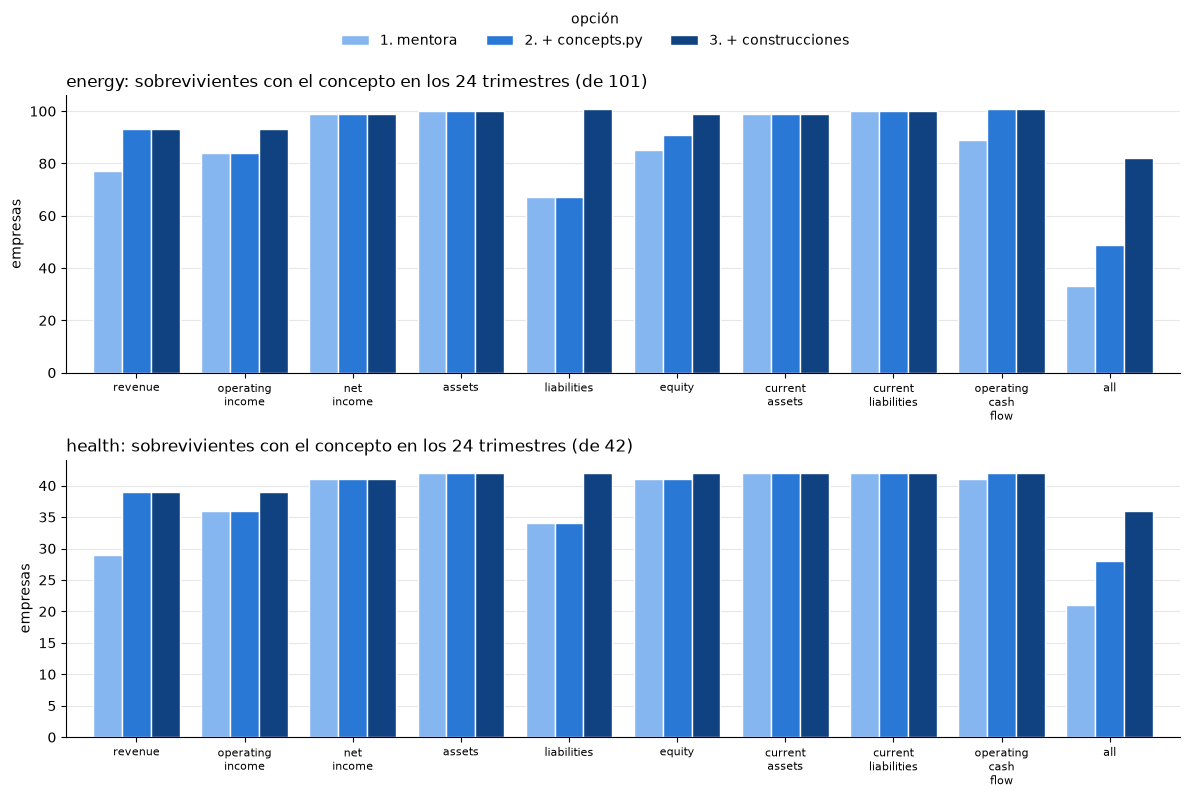

In [9]:
import matplotlib.pyplot as plt

# one blue, light -> dark: each option adds sources to the previous one
COLORS = ["#86b6ef", "#2a78d6", "#104281"]

fig, axes = plt.subplots(2, 1, figsize=(12, 8))
for ax, s in zip(axes, ["energy", "health"]):
    df.xs(s, axis=1, level="sector").plot.bar(
        ax=ax, color=COLORS, width=0.8, edgecolor="white", linewidth=1
    )
    ax.set_title(
        f"{s}: sobrevivientes con el concepto en los 24 trimestres (de {(sector == s).sum()})",
        loc="left",
    )
    ax.set_ylabel("empresas")
    ax.set_xticklabels(
        [label.replace("_", "\n") for label in df.index], rotation=0, fontsize=8
    )
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.get_legend().remove()

# one legend for both charts, above them
fig.legend(
    *axes[0].get_legend_handles_labels(),
    title="opción",
    frameon=False,
    loc="upper center",
    ncol=3,
)
fig.tight_layout(rect=(0, 0, 1, 0.93))

## Resultado

Sobrevivientes con los 9 conceptos en los 24 trimestres:

| Opción | Energía (de 101) | Salud (de 42) | Total |
|---|---|---|---|
| 1. Mentora | 33 | 21 | 54 |
| 2. + `concepts.py` | 49 | 28 | 77 |
| 3. + construcciones | 82 | 36 | 118 |

- **Opción 2:** suma ingresos (energía de 77 a 93, salud de 29 a 39), flujo operativo (energía de 89 a 101) y patrimonio (energía de 85 a 91).
- **Opción 3:** suma sobre todo pasivo (energía de 67 a 101, salud de 34 a 42), resultado operativo (energía de 84 a 93) y patrimonio (energía de 91 a 99).
- Con la opción 3, los conceptos que más limitan son ingresos y resultado operativo (93 de 101 en energía, 39 de 42 en salud). No tienen otra construcción.

PRECAUCIÓN: la opción 1 incluye `ProfitLoss` como alternativo de la ganancia neta. Con esta prioridad, nuestra construcción `ProfitLoss` − minoritarios nunca se usa: si hay `ProfitLoss`, la opción 1 ya tiene valor. `ProfitLoss` solo coincide con `NetIncomeLoss` en el 54,8% de los períodos con los dos tags (`concepts_justification.ipynb`, cell-32).

PRECAUCIÓN: la tabla mide si hay un valor, no si el valor es correcto. Cada construcción coincide con su tag en el 89,7% al 100% de los períodos (`docs/ratios.md`).